Длина первого ряда (smoothing_ts1): 144
Длина второго ряда (smoothing_ts2): 1000


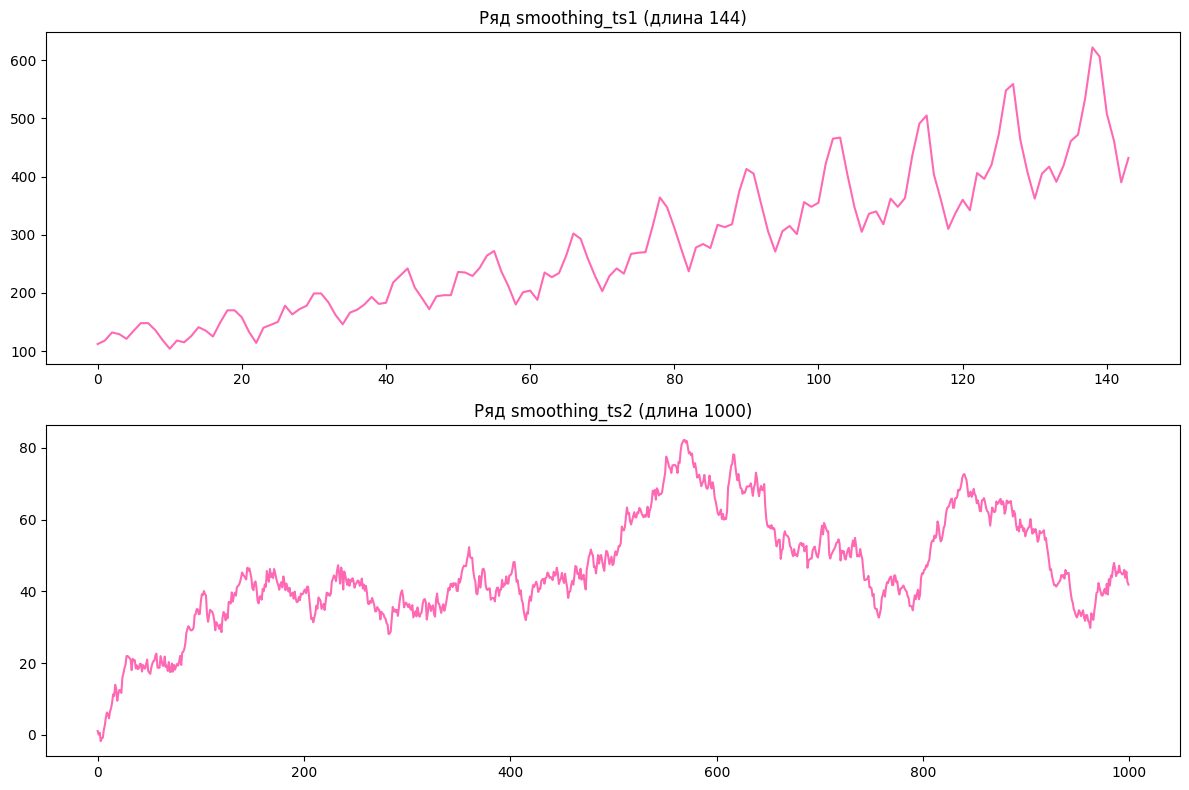


Анализ ряда: smoothing_ts1 (Хольт-Винтерс add/mul)
Размер train: 139, Размер test: 5
Последние 5 реальных значений (Test): [606 508 461 390 432]
Прогноз модели: [626.7  512.6  447.68 392.5  432.18]
MSE модели: 126.70


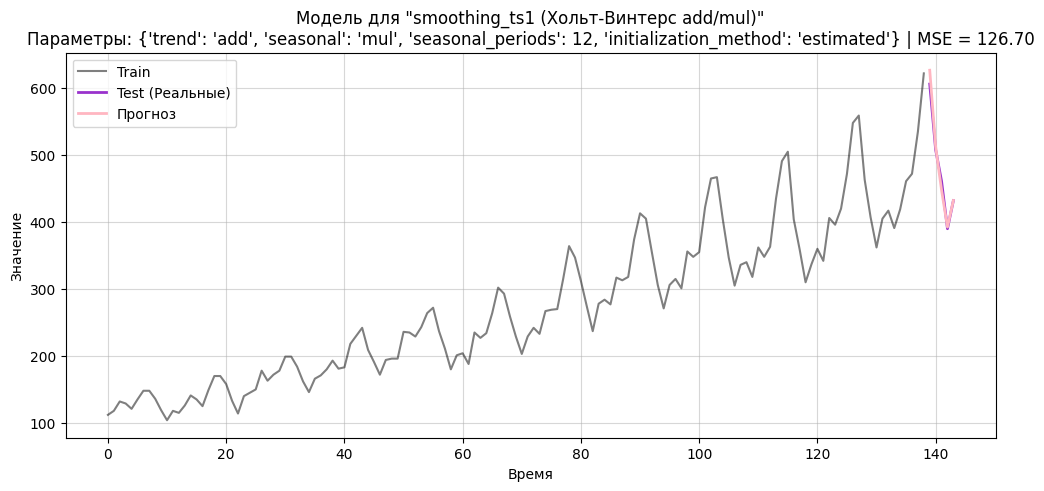


Анализ ряда: smoothing_ts2 (Простое сглаживание)
Размер train: 995, Размер test: 5
Последние 5 реальных значений (Test): [46.04384344 43.84007603 45.51910124 42.64285148 41.89935838]
Прогноз модели: [44.78 44.78 44.78 44.78 44.78]
MSE модели: 3.18


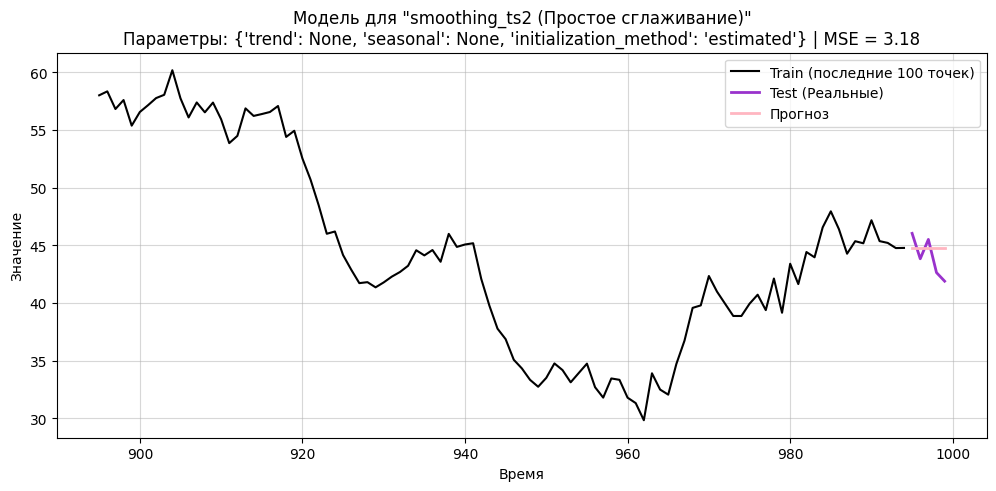

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests
from io import BytesIO
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def mse(observations, estimates):
    """
    INPUT:
        observations - numpy array of observed values
        estimates - numpy array of estimated (predicted) values
    OUTPUT:
        Mean Square Error value
    """
    assert type(observations) == type(np.array([])), "'observations' must be a numpy array"
    assert type(estimates) == type(np.array([])), "'estimates' must be a numpy array"
    assert len(observations) == len(estimates), "Arrays must be of equal length"
    difference = observations - estimates
    sq_diff = difference ** 2
    return np.mean(sq_diff)

# Загрузка данных и создание временных переменных
try:
    response1 = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts1.npy?download=1")
    response1.raise_for_status()
    smoothing_ts1 = np.load(BytesIO(response1.content))
    print(f"Длина первого ряда (smoothing_ts1): {len(smoothing_ts1)}")

    response2 = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts4_4.npy?download=1")
    response2.raise_for_status()
    smoothing_ts2 = np.load(BytesIO(response2.content))
    print(f"Длина второго ряда (smoothing_ts2): {len(smoothing_ts2)}")

    mytime1 = np.arange(len(smoothing_ts1))
    mytime2 = np.arange(len(smoothing_ts2))
except Exception as e:
    print(f"Ошибка при загрузке данных: {e}")
    sys.exit()

# Визуальный анализ
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
ax1.plot(mytime1, smoothing_ts1, color='hotpink')
ax1.set_title('Ряд smoothing_ts1 (длина 144)')
ax2.plot(mytime2, smoothing_ts2, color='hotpink')
ax2.set_title('Ряд smoothing_ts2 (длина 1000)')
plt.tight_layout()
plt.show()

# Обработка каждого ряда
def analyze_and_plot(series, time, name, model_params, plot_zoom=True):
    print(f"\nАнализ ряда: {name}")

    n_test = 5
    train = series[:-n_test]
    test = series[-n_test:]
    train_t = time[:-n_test]
    test_t = time[-n_test:]

    print(f"Размер train: {len(train)}, Размер test: {len(test)}")
    print(f"Последние 5 реальных значений (Test): {test}")

    try:
        # Создание и обучение модели
        model = ExponentialSmoothing(
            train,
            **model_params
        ).fit()

        # Прогноз
        forecast = model.forecast(steps=n_test)

        print(f"Прогноз модели: {np.round(forecast, 2)}")

        # Расчет MSE
        error = mse(test, forecast)
        print(f"MSE модели: {error:.2f}")

        # Визуализация
        plt.figure(figsize=(12, 5))

        if plot_zoom:
            zoom = min(100, len(train))
            plt.plot(train_t[-zoom:], train[-zoom:], 'k-', label='Train (последние 100 точек)')
        else:
            plt.plot(train_t, train, 'k-', alpha=0.5, label='Train')

        plt.plot(test_t, test, color='darkorchid', markersize=8, linewidth=2, label='Test (Реальные)')
        plt.plot(test_t, forecast, color='lightpink', markersize=8, linewidth=2, label='Прогноз')

        plt.title(f'Модель для "{name}"\nПараметры: {model_params} | MSE = {error:.2f}')
        plt.xlabel('Время')
        plt.ylabel('Значение')
        plt.legend()
        plt.grid(True, alpha=0.5)
        plt.show()


    except Exception as e:
        print(f"Ошибка: {e}")
        return None

# Анализ smoothing_ts1(Модель Хольта-Винтерса)
params_ts1 = {
    'trend': 'add',
    'seasonal': 'mul',
    'seasonal_periods': 12,
    'initialization_method': 'estimated'
}
analyze_and_plot(smoothing_ts1, mytime1, "smoothing_ts1 (Хольт-Винтерс add/mul)", params_ts1, plot_zoom=False)

# Анализ smoothing_ts1(Простое сглаживание)
params_ts2 = {
    'trend': None,
    'seasonal': None,
    'initialization_method': 'estimated'
}
analyze_and_plot(smoothing_ts2, mytime2, "smoothing_ts2 (Простое сглаживание)", params_ts2, plot_zoom=True)

Анализ ряда smoothing_ts1 (длина 144)

Визуальный анализ показал наличие выраженного тренда и сезонности с периодом 12. Амплитуда сезонных колебаний имеет свойство изменяться вместе с уровнем ряда, что указывает на мультипликативную природу сезонности. Для учета всех трех компонент (уровень, тренд, сезонность) была выбрана тройная модель Хольта-Винтерса с параметрами trend='add' и seasonal='mul'. Применение простых моделей (одинарной или двойной) в данном случае было бы неэффективно, так как они не способны уловить сезонные паттерны и дали бы огромную ошибку.

Модель показала отличный результат с MSE = 126.70. Как видно на графике, прогноз (розовые точки) практически идеально ложится на траекторию реальных тестовых данных (фиолетовые точки) и точно повторяет сезонную волну. Это говорит о том, что модель успешно выявила скрытые закономерности ряда и сделала высокоточный прогноз.

Анализ ряда smoothing_ts2 (длина 1000)

Метод и аргументация: Визуальный анализ длинного ряда не выявил стабильного тренда или четкой периодической сезонности. По своей природе этот ряд ведет себя как «случайное блуждание», где каждое следующее значение в значительной степени зависит от предыдущего, а долгосрочное направление непредсказуемо из-за шума. В таких условиях применение модели с трендом (Хольта) приводит к переобучению и попытке продолжить случайные выбросы, что дает худший результат (MSE ≈ 3.35). Поэтому было выбрано простое экспоненциальное сглаживание (trend=None, seasonal=None).

Модель показала MSE = 3.18, что является отличным показателем для случайного блуждания. Визуализация прогноза (с приближением на последние 100 точек) демонстрирует горизонтальную линию: оптимальный параметр сглаживания alpha стремится к 1 (≈0.979), из-за чего модель практически игнорирует историю и просто проецирует в будущее последнее известное значение. Реальные тестовые данные ушли вниз, и прогноз не смог этого предугадать. Однако это не является ошибкой модели — это математически доказанный факт: для случайного блуждания невозможно предсказать направление движения, и лучший прогноз — это именно последнее известное значение.

Общий итог:
Упражнение наглядно демонстрирует, что универсального метода сглаживания не существует. Выбор модели должен строго основываться на структуре данных: для рядов с трендом и сезонностью необходимо применять сложные модели (Хольт-Винтерс), обеспечивающие высокую точность, в то время как для случайных блужданий лучшим решением является простое сглаживание, устойчивое к шуму.

